In [5]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain+.txt"

cols = ["duration","protocol_type","service","flag","src_bytes","dst_bytes",
 "land","wrong_fragment","urgent","hot","num_failed_logins","logged_in",
 "num_compromised","root_shell","su_attempted","num_root","num_file_creations",
 "num_shells","num_access_files","num_outbound_cmds","is_host_login",
 "is_guest_login","count","srv_count","serror_rate","srv_serror_rate",
 "rerror_rate","srv_rerror_rate","same_srv_rate","diff_srv_rate",
 "srv_diff_host_rate","dst_host_count","dst_host_srv_count",
 "dst_host_same_srv_rate","dst_host_diff_srv_rate",
 "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate",
 "dst_host_serror_rate","dst_host_srv_serror_rate","dst_host_rerror_rate",
 "dst_host_srv_rerror_rate","label","difficulty"]

df = pd.read_csv(url, names=cols)

df.shape

(125973, 43)

## 1. Size of the dataset
125,973 connections, each with 43 columns.

In [7]:
df.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [8]:
df["label"].value_counts()

label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64

## 2. What kinds of traffic are in it?
- Most common: normal (67,343), neptune/SYN flood (41,214), satan/probe (3,633)
- Some attacks are very rare: spy (2), perl (3), phf (4)
- Rare attacks will be hard for a model to learn

In [10]:
df["is_attack"] = df["label"] != "normal"
df["is_attack"].value_counts()

is_attack
False    67343
True     58630
Name: count, dtype: int64

## 3. How much is attack traffic?
58,630 of 125,973 connections (~47%) are attacks. Much higher than a real network.

In [11]:
df.groupby("is_attack")["src_bytes"].median()

is_attack
False    233.0
True       0.0
Name: src_bytes, dtype: float64

In [12]:
df.groupby("is_attack")["src_bytes"].mean()

is_attack
False    13133.279331
True     82820.141327
Name: src_bytes, dtype: float64

markdown
## 4. What's different about attacks?
- Bytes sent: typical attack sends 0 bytes, typical normal connection sends 233.
  Floods and scans don't send real data. (Mean is misleading here because of a few huge attacks.)

In [13]:
df.groupby("is_attack")["count"].median()

is_attack
False      4.0
True     138.0
Name: count, dtype: float64

- Connection rate (`count`): typical attack has 138 connections to the same host
  in 2 seconds vs 4 for normal traffic, ~35x more. Matches floods and scans.

## Charts

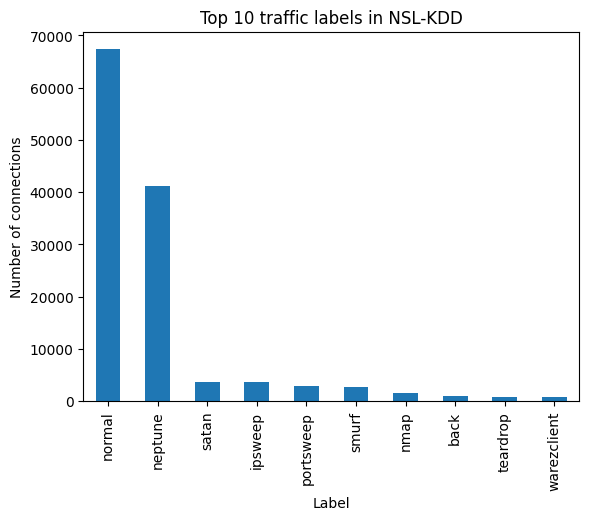

In [14]:
top = df["label"].value_counts().head(10)

top.plot(kind="bar")
plt.title("Top 10 traffic labels in NSL-KDD")
plt.xlabel("Label")
plt.ylabel("Number of connections")
plt.show()

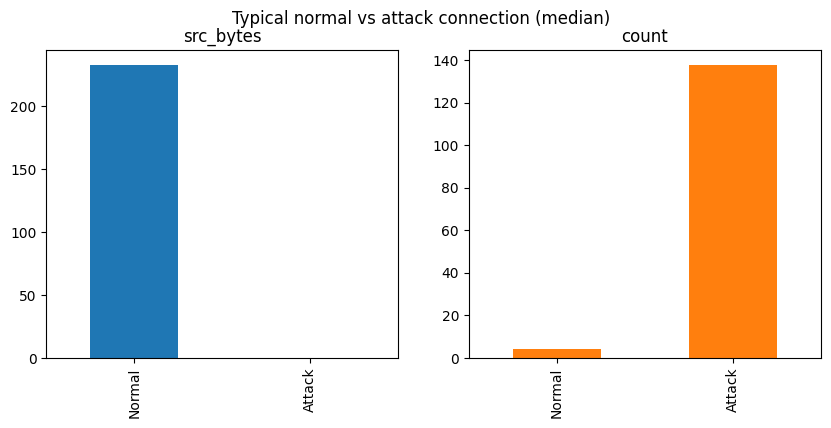

In [16]:
summary = df.groupby("is_attack")[["src_bytes", "count"]].median()
summary.index = ["Normal", "Attack"]

summary.plot(kind="bar", subplots=True, layout=(1, 2), figsize=(10, 4), legend=False)
plt.suptitle("Typical normal vs attack connection (median)")
plt.show()